In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
    ("xgboost",   "xgboost==2.0.3",        "xgboost==2.0.3"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B3 – Phát Hiện Tấn Công Mạng Bằng Học Máy
## Phân Loại Nhị Phân – Dataset CICMAL2017

## 1. Import Thư Viện

In [41]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

# ── Tiền xử lý ───────────────────────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# ── Các mô hình học máy ───────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# ── Đánh giá mô hình ─────────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay,
    ConfusionMatrixDisplay
)

# ── Style đồ thị ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
SEED = 42
np.random.seed(SEED)

print("✅ Import thư viện thành công!")
print(f"   • scikit-learn, xgboost, pandas, numpy, matplotlib, seaborn")

✅ Import thư viện thành công!
   • scikit-learn, xgboost, pandas, numpy, matplotlib, seaborn


## 2. Cấu Hình Đường Dẫn & Tham Số

In [42]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════

from pathlib import Path

# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
# ROOT_DIR: thư mục làm việc hiện tại (working directory)
# CSV_PATH: đường dẫn tới file dataset chính
ROOT_DIR = Path.cwd()
CSV_PATH = ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv"


# ==========================
# NHÃN (LABELS)
# ==========================
# BINARY_LABEL:
#   - 0 → Benign (bình thường)
#   - 1 → Malware (tấn công)
#
# CATEGORY_LABEL:
#   - Nhãn đa lớp (multi-class)
#   - Ví dụ: Adware, Ransomware, Spyware,...
BINARY_LABEL = "Binary Label"
CATEGORY_LABEL = "Cat_Label"


# ==========================
# CHIA DỮ LIỆU (TRAIN / TEST)
# ==========================
# TEST_SIZE: tỷ lệ dữ liệu dùng để test (20%)
# RANDOM_STATE: seed để đảm bảo kết quả có thể tái lập
TEST_SIZE = 0.2
RANDOM_STATE = SEED


# ==========================
# CROSS-VALIDATION
# ==========================
# CV_FOLDS: số fold dùng trong K-Fold Cross Validation
CV_FOLDS = 5


# ==========================
# CÁC CỘT KHÔNG DÙNG LÀM FEATURE
# ==========================
# META_COLS:
# - Các cột định danh hoặc nhãn
# - Không đưa vào mô hình để tránh data leakage
META_COLS = [
    "Flow ID",  # ID của luồng mạng
    "Src IP",  # IP nguồn
    "Dst IP",  # IP đích
    "Timestamp",  # thời gian
    "Label",  # nhãn multi-class (target)
    "Label",  # nhãn binary (target)
]


# ==========================
# LOG THÔNG TIN CẤU HÌNH
# ==========================
print("✅ Cấu hình xong!")
print(f"   Dataset   → {CSV_PATH}")
print(f"   Test size → {TEST_SIZE*100:.0f}%")
print(f"   CV folds  → {CV_FOLDS}")
print(f"   Labels    → Binary: {BINARY_LABEL} | Multi: {CATEGORY_LABEL}")

✅ Cấu hình xong!
   Dataset   → c:\Desktop\VANN\BÁO CÁO THỰC HÀNH\CV4.1\Dataset\category_CICMAL2017_dataset.csv
   Test size → 20%
   CV folds  → 5
   Labels    → Binary: Binary Label | Multi: Cat_Label


## 3. Hàm Tiện Ích Dùng Chung

In [43]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def preprocess(df, label_col, meta_cols=None):
    """
    Làm sạch và chuẩn hóa DataFrame:
      1. Loại bỏ cột meta (IP, timestamp, v.v.)
      2. Thay thế Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median (cột số)
      4. Loại cột phương sai = 0 (không có thông tin)
      5. Chuẩn hóa StandardScaler
    Trả về: X (ma trận đặc trưng đã chuẩn hóa), y (nhãn), feature_names
    """
    if meta_cols is None:
        meta_cols = []

    df = df.copy()
    df.columns = df.columns.str.strip()  # xóa khoảng trắng tên cột

    # Xác định cột đặc trưng số (loại cột meta và nhãn)
    drop_cols = [c for c in meta_cols if c in df.columns and c != label_col]
    feature_cols = [
        c
        for c in df.select_dtypes(include=np.number).columns
        if c not in drop_cols and c != label_col
    ]

    X_raw = df[feature_cols].copy()

    # Thay Inf → NaN, rồi điền median
    X_raw.replace([np.inf, -np.inf], np.nan, inplace=True)
    X_raw.fillna(X_raw.median(), inplace=True)

    # Loại đặc trưng không đổi (phương sai = 0) → vô ích với mô hình
    zero_var = X_raw.columns[X_raw.var() == 0].tolist()
    if zero_var:
        print(f"   ⚠ Loại {len(zero_var)} cột phương sai = 0: {zero_var[:5]}...")
        X_raw.drop(columns=zero_var, inplace=True)

    feature_names = X_raw.columns.tolist()

    # Chuẩn hóa Z-score (mean=0, std=1) – quan trọng cho LR, KNN
    scaler = StandardScaler()
    X = scaler.fit_transform(X_raw)

    # Mã hóa nhãn thành số nguyên
    y_raw = df[label_col].astype(str).str.strip()
    le = LabelEncoder()
    y = le.fit_transform(y_raw)

    return X, y, feature_names, le, scaler


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
def evaluate_model(
    model,
    X_train,
    X_test,
    y_train,
    y_test,
    model_name,
    is_binary=True,
    label_names=None,
):
    """
    Huấn luyện và đánh giá model với các metric:

    Metrics:
      - Accuracy
      - Precision
      - Recall
      - F1-score
      - ROC-AUC (binary hoặc multi-class)

    Returns:
      result dict + predictions + trained model
    """

    # Train model
    model.fit(X_train, y_train)

    # Dự đoán label
    y_pred = model.predict(X_test)

    # Chọn cách tính metric
    avg = "binary" if is_binary else "weighted"

    # ==========================
    # Tính các chỉ số cơ bản
    # ==========================
    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average=avg, zero_division=0),
        "Recall": recall_score(y_test, y_pred, average=avg, zero_division=0),
        "F1": f1_score(y_test, y_pred, average=avg, zero_division=0),
    }

    # ==========================
    # ROC-AUC
    # ==========================
    # Binary classification
    if is_binary and hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)
        if y_prob.shape[1] == 2:
            y_prob = y_prob[:, 1]
        else:
            # Trường hợp chỉ có 1 lớp trong tập huấn luyện
            # Vẫn lấy cột duy nhất, nhưng ROC-AUC sẽ không có ý nghĩa
            y_prob = y_prob[:, 0]
        result["ROC-AUC"] = roc_auc_score(y_test, y_prob)

    # Multi-class classification
    elif not is_binary and hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)
        result["ROC-AUC"] = roc_auc_score(
            y_test, y_prob, multi_class="ovr", average="weighted"
        )
    else:
        result["ROC-AUC"] = np.nan

    return result, y_pred, model


# ════════════════════════════════════════════════════════════════════════════
# HÀM VẼ CONFUSION MATRIX
# ════════════════════════════════════════════════════════════════════════════
def plot_confusion(y_test, y_pred, label_names, title, ax):
    """
    Vẽ confusion matrix chuẩn hóa theo hàng (true distribution).

    Ý nghĩa:
      - Hàng = ground truth
      - Cột = prediction
      - Giá trị = tỷ lệ (%)
    """

    cm = confusion_matrix(y_test, y_pred, normalize="true")

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)

    disp.plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f", xticks_rotation=30
    )

    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel("Dự đoán", fontsize=9)
    ax.set_ylabel("Thực tế", fontsize=9)
    ax.tick_params(labelsize=7)


# ════════════════════════════════════════════════════════════════════════════
# HÀM VẼ BẢNG KẾT QUẢ MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
def plot_results_bar(results_df, title, save_name):
    """Bar chart so sánh các chỉ số của nhiều mô hình."""
    metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
    metrics = [m for m in metrics if m in results_df.columns]

    x = np.arange(len(results_df))
    width = 0.15
    colors = ["#2196F3", "#4CAF50", "#FF9800", "#E91E63", "#9C27B0"]

    fig, ax = plt.subplots(figsize=(12, 5))
    for i, (metric, color) in enumerate(zip(metrics, colors)):
        offset = (i - len(metrics) / 2 + 0.5) * width
        bars = ax.bar(
            x + offset, results_df[metric], width, label=metric, color=color, alpha=0.85
        )
        for bar in bars:
            h = bar.get_height()
            if not np.isnan(h):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    h + 0.005,
                    f"{h:.3f}",
                    ha="center",
                    va="bottom",
                    fontsize=6.5,
                )

    ax.set_xticks(x)
    ax.set_xticklabels(results_df["Model"], rotation=15, ha="right", fontsize=9)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8, ncol=len(metrics))
    ax.axhline(0.9, color="red", linestyle="--", linewidth=0.7, alpha=0.4)
    ax.text(len(x) - 0.5, 0.905, "ngưỡng 0.9", fontsize=7, color="red", alpha=0.6)
    plt.tight_layout()
    # plt.savefig(save_name, bbox_inches='tight')
    plt.show()
    print(f"✅ Đã lưu {save_name}")


print("✅ Đã định nghĩa xong các hàm tiện ích!")

✅ Đã định nghĩa xong các hàm tiện ích!


---
# Phân Loại Nhị Phân (Binary Classification)

> **Bài toán:** Dự đoán một luồng mạng là **Benign (0)** hay **Malware (1)**
>
> Đây là bước phát hiện xâm nhập cơ bản nhất – giống như bảo vệ tại cổng vào.


### A1. Tải & Tiền Xử Lý Dữ Liệu Nhị Phân

In [44]:
print("═" * 60)
print("TẢI DỮ LIỆU NHỊ PHÂN")
print("═" * 60)

# Đọc từ dataset chung
df_bin = pd.read_csv(CSV_PATH, low_memory=False)

print(f"Shape gốc: {df_bin.shape}")
print(f"\nPhân phối nhãn gốc:")
print(df_bin[BINARY_LABEL].value_counts().rename({0: "Benign(0)", 1: "Malware(1)"}))

# ── Tiền xử lý ────────────────────────────────────────────────────────────────
X_bin, y_bin, feat_bin, le_bin, scaler_bin = preprocess(df_bin, BINARY_LABEL, META_COLS)

print(f"\n✅ Sau tiền xử lý:")
print(f"   Số đặc trưng  : {X_bin.shape[1]}")
print(f"   Số mẫu        : {X_bin.shape[0]:,}")
print(f"   Classes       : {le_bin.classes_}")

# ── Chia train/test (stratified) ─────────────────────────────────────────────
X_bin_tr, X_bin_te, y_bin_tr, y_bin_te = train_test_split(
    X_bin, y_bin, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_bin
)

print(
    f"\n📦 Chia tập dữ liệu (stratified {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):"
)
print(f"   Train: {X_bin_tr.shape[0]:,} mẫu")
print(f"   Test : {X_bin_te.shape[0]:,} mẫu")

════════════════════════════════════════════════════════════
TẢI DỮ LIỆU NHỊ PHÂN
════════════════════════════════════════════════════════════
Shape gốc: (22192, 86)

Phân phối nhãn gốc:
Malware(1)    17153
Benign(0)      5039
Name: Binary Label, dtype: int64
   ⚠ Loại 8 cột phương sai = 0: ['CWE Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate']...

✅ Sau tiền xử lý:
   Số đặc trưng  : 72
   Số mẫu        : 22,192
   Classes       : ['0' '1']

📦 Chia tập dữ liệu (stratified 80/20):
   Train: 17,753 mẫu
   Test : 4,439 mẫu


### A2. Định Nghĩa Các Mô Hình

In [45]:
# ════════════════════════════════════════════════════════════════════════════
# DANH SÁCH MÔ HÌNH PHÂN LOẠI NHỊ PHÂN
# ════════════════════════════════════════════════════════════════════════════
#
# Logistic Regression – đơn giản, nhanh, dễ giải thích; baseline tốt
# Decision Tree       – dễ trực quan hóa, có thể overfit nếu sâu
# Random Forest       – ensemble của nhiều cây, robust, ít overfit
# XGBoost             – gradient boosting mạnh nhất; thường đạt kết quả cao nhất
# KNN                 – dựa trên khoảng cách; nhạy với chuẩn hóa dữ liệu
# ────────────────────────────────────────────────────────────────────────────

bin_models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,           # giới hạn độ sâu → tránh overfit
        min_samples_leaf=5,     # mỗi lá phải có ≥ 5 mẫu
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,       # 100 cây quyết định
        max_depth=15,
        min_samples_leaf=3,
        n_jobs=-1,              # dùng tất cả CPU core
        random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,      # bước học; nhỏ hơn = cẩn thận hơn
        subsample=0.8,          # mỗi cây dùng 80% dữ liệu → tránh overfit
        colsample_bytree=0.8,   # mỗi cây dùng 80% đặc trưng
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=SEED,
        verbosity=0
    ),
}

print("✅ Đã định nghĩa 3 mô hình nhị phân:")
for name in bin_models:
    print(f"   • {name}")


✅ Đã định nghĩa 3 mô hình nhị phân:
   • Decision Tree
   • Random Forest
   • XGBoost


### A3. Huấn Luyện & Đánh Giá

In [46]:
from time import time

bin_results  = []
bin_preds    = {}
bin_trained  = {}

print("Đang huấn luyện các mô hình nhị phân...\n")
print(f"{'Mô hình':<22} {'Acc':>7} {'Prec':>7} {'Recall':>8} {'F1':>7} {'AUC':>7} {'Time':>7}")
print("─" * 70)

for name, model in bin_models.items():
    t0 = time()
    result, y_pred, trained_model = evaluate_model(
        model, X_bin_tr, X_bin_te, y_bin_tr, y_bin_te,
        name, is_binary=True
    )
    elapsed = time() - t0

    bin_results.append(result)
    bin_preds[name]   = y_pred
    bin_trained[name] = trained_model

    auc_str = f"{result['ROC-AUC']:.4f}" if not np.isnan(result['ROC-AUC']) else "  N/A "
    print(f"{name:<22} {result['Accuracy']:>7.4f} {result['Precision']:>7.4f} "
          f"{result['Recall']:>8.4f} {result['F1']:>7.4f} {auc_str:>7} {elapsed:>6.1f}s")

bin_df = pd.DataFrame(bin_results).set_index('Model')
print("\n" + "─" * 70)
print("\n📊 Mô hình tốt nhất theo F1:")
best_bin = bin_df['F1'].idxmax()
print(f"   → {best_bin}  (F1 = {bin_df.loc[best_bin,'F1']:.4f})")


Đang huấn luyện các mô hình nhị phân...

Mô hình                    Acc    Prec   Recall      F1     AUC    Time
──────────────────────────────────────────────────────────────────────
Decision Tree           0.9930  0.9919   0.9991  0.9955  0.9907    1.0s
Random Forest           0.9941  0.9925   1.0000  0.9962  0.9956    2.0s
XGBoost                 0.9946  0.9936   0.9994  0.9965  0.9970    0.7s

──────────────────────────────────────────────────────────────────────

📊 Mô hình tốt nhất theo F1:
   → XGBoost  (F1 = 0.9965)


### A4. So Sánh Hiệu Suất Các Mô Hình

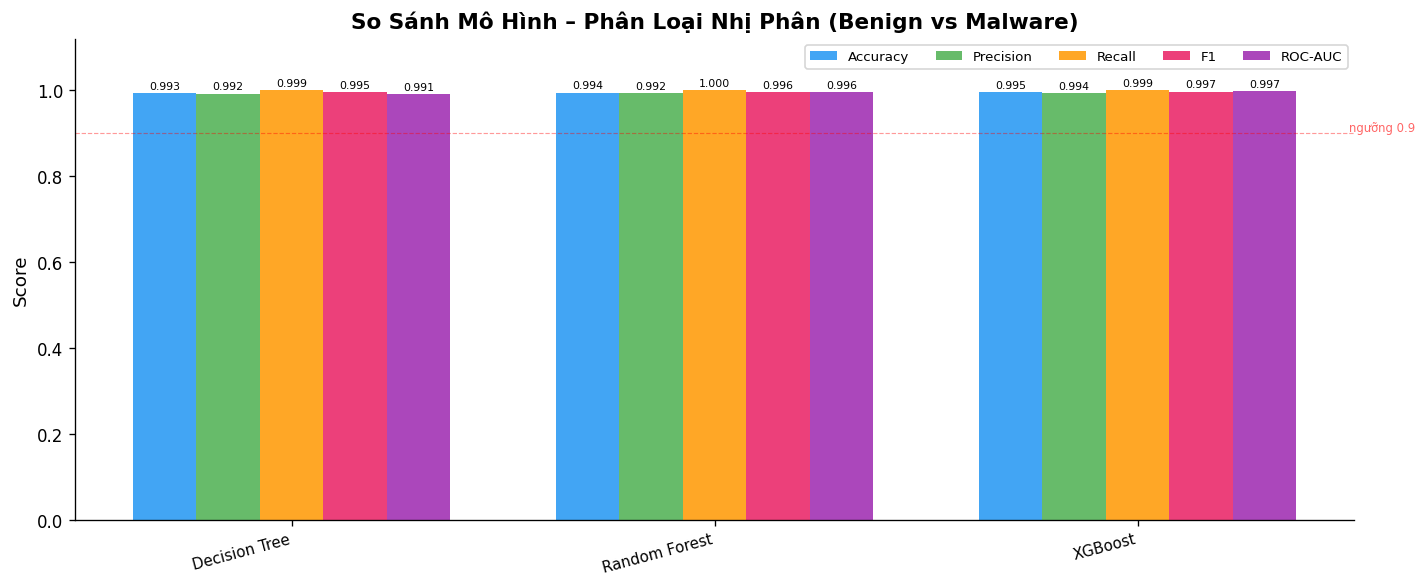

✅ Đã lưu binary_model_comparison.png

📋 Bảng kết quả đầy đủ:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Decision Tree,0.9930,0.9919,0.9991,0.9955,0.9907
Random Forest,0.9941,0.9925,1.0000,0.9962,0.9956
XGBoost,0.9946,0.9936,0.9994,0.9965,0.9970


In [47]:
plot_results_bar(
    bin_df.reset_index(),
    title="So Sánh Mô Hình – Phân Loại Nhị Phân (Benign vs Malware)",
    save_name="binary_model_comparison.png"
)
print("\n📋 Bảng kết quả đầy đủ:")
display(bin_df.style
        .format('{:.4f}')
        .background_gradient(cmap='YlGn', axis=0)
        .set_caption("Kết quả phân loại nhị phân (test set)"))


### A5. Confusion Matrix Từng Mô Hình

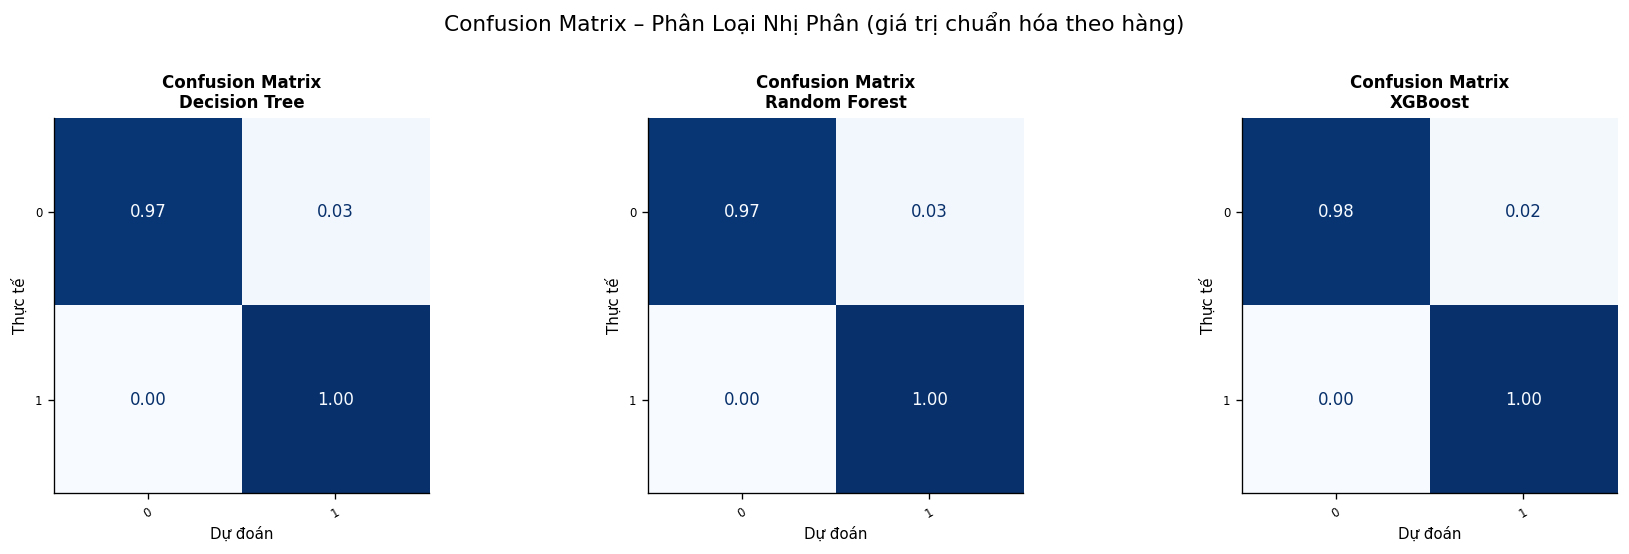

In [48]:
# Confusion Matrix cho thấy:
#   - Hàng = Nhãn thực tế (True)
#   - Cột = Nhãn dự đoán (Predicted)
#   - Diagonal chính = dự đoán đúng
#   - Giá trị ngoài diagonal = lỗi (False Positive / False Negative)
#
# Chúng ta chuẩn hóa theo hàng → giá trị là tỉ lệ (0.0 – 1.0)
# VD: [0][1] = 0.05 → 5% mẫu Benign bị dự đoán nhầm thành Malware

bin_label_names = le_bin.classes_
n_models = len(bin_models)
ncols = 3
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4.5))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(bin_preds.items()):
    plot_confusion(y_bin_te, y_pred, bin_label_names,
                   f"Confusion Matrix\n{name}", axes[i])

# Ẩn subplot thừa
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Confusion Matrix – Phân Loại Nhị Phân (giá trị chuẩn hóa theo hàng)",
             fontsize=13, y=1.01)
plt.tight_layout()
# plt.savefig("binary_confusion_matrices.png", bbox_inches='tight')
plt.show()


### A6. Đường Cong ROC (Nhị Phân)

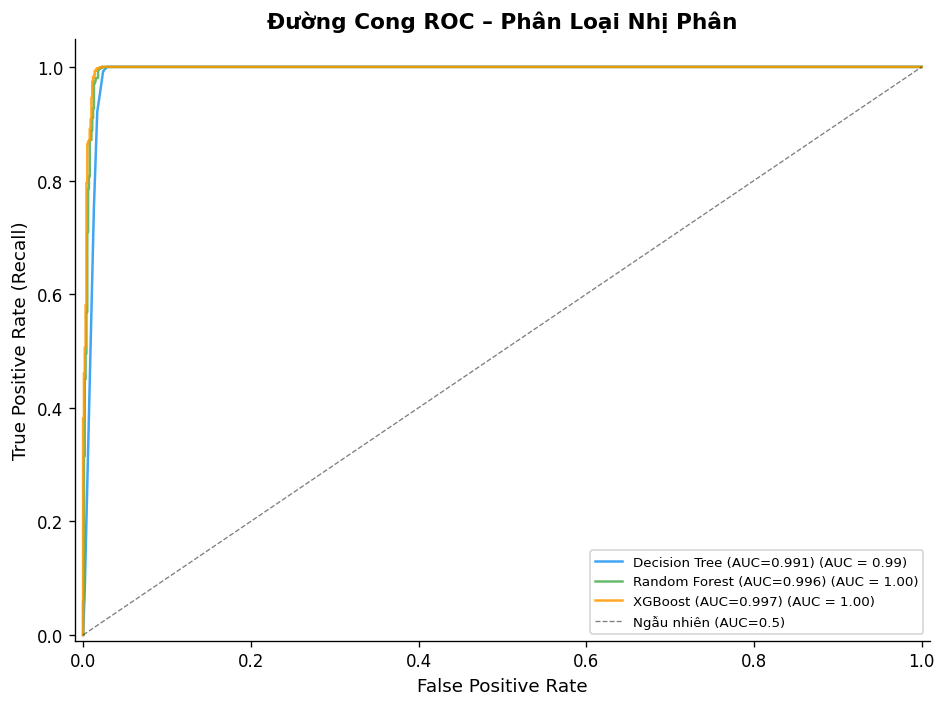

✅ Đã lưu binary_roc_curves.png


In [49]:
# ROC Curve (Receiver Operating Characteristic):
#   - Trục X: False Positive Rate (FPR) = FP / (FP + TN)
#   - Trục Y: True Positive Rate (TPR) = TP / (TP + FN) = Recall
#   - AUC (Area Under Curve): càng gần 1.0 càng tốt
#   - Đường chéo (AUC=0.5) = mô hình đoán ngẫu nhiên
#
# Mô hình tốt: đường ROC càng "phồng" về góc trên-trái càng cao AUC

fig, ax = plt.subplots(figsize=(8, 6))

colors_roc = ['#2196F3','#4CAF50','#FF9800','#E91E63','#9C27B0']

for (name, model), color in zip(bin_trained.items(), colors_roc):
    if hasattr(model, 'predict_proba'):
        RocCurveDisplay.from_estimator(
            model, X_bin_te, y_bin_te, ax=ax,
            name=f"{name} (AUC={bin_df.loc[name,'ROC-AUC']:.3f})",
            color=color, linewidth=1.5, alpha=0.85
        )

# Đường ngẫu nhiên (baseline)
ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, alpha=0.5, label='Ngẫu nhiên (AUC=0.5)')
ax.set_title("Đường Cong ROC – Phân Loại Nhị Phân")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc='lower right', fontsize=8)
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.05)
plt.tight_layout()
# plt.savefig("binary_roc_curves.png", bbox_inches='tight')
plt.show()
print("✅ Đã lưu binary_roc_curves.png")


### A7. Feature Importance – Đặc Trưng Quan Trọng (Nhị Phân)

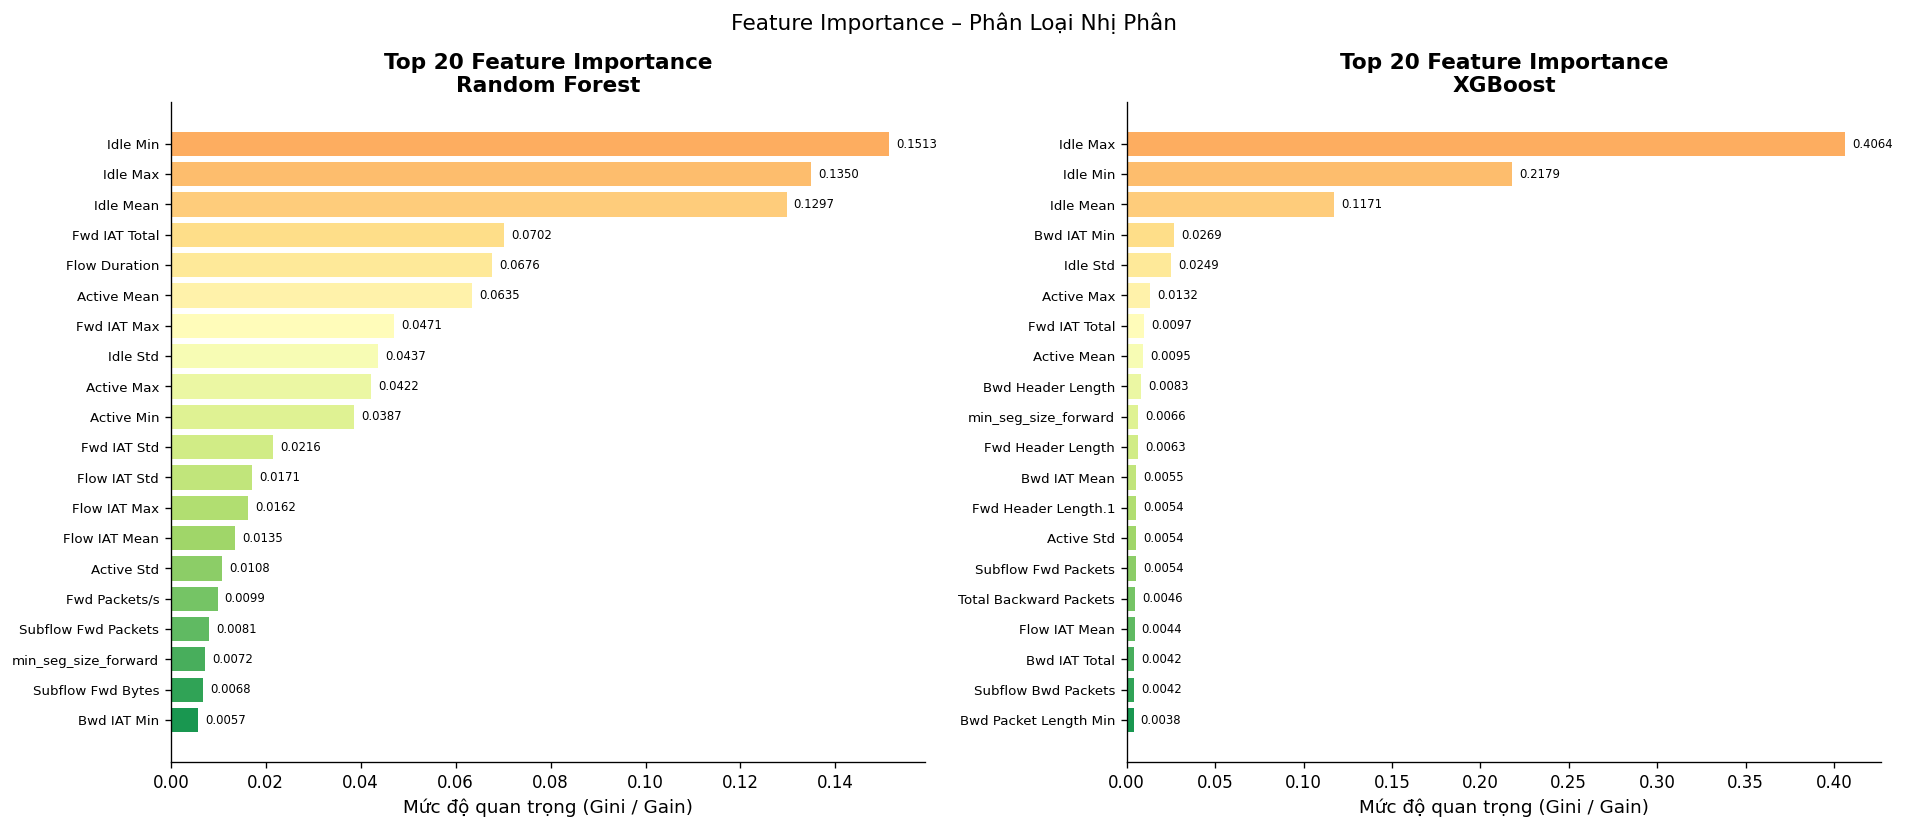

✅ Đã lưu binary_feature_importance.png

🔍 Top 10 đặc trưng quan trọng nhất (Random Forest – Binary):
    1. ██████████████████████████████ 0.1513  Idle Min
    2. ██████████████████████████     0.1350  Idle Max
    3. █████████████████████████      0.1297  Idle Mean
    4. █████████████                  0.0702  Fwd IAT Total
    5. █████████████                  0.0676  Flow Duration
    6. ████████████                   0.0635  Active Mean
    7. █████████                      0.0471  Fwd IAT Max
    8. ████████                       0.0437  Idle Std
    9. ████████                       0.0422  Active Max
   10. ███████                        0.0387  Active Min


In [50]:
# Feature Importance cho biết đặc trưng nào ảnh hưởng nhiều nhất
# đến quyết định phân loại của mô hình.
#
# Random Forest & XGBoost sử dụng "impurity decrease" hoặc "gain"
# để tính tầm quan trọng của từng đặc trưng.

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
TOP_N_FEAT = 20

for ax, model_name in zip(axes, ["Random Forest", "XGBoost"]):
    model = bin_trained[model_name]
    importances = model.feature_importances_
    feat_imp = pd.Series(importances, index=feat_bin).nlargest(TOP_N_FEAT)

    colors_fi = plt.cm.RdYlGn(np.linspace(0.3, 0.9, TOP_N_FEAT))[::-1]
    bars = ax.barh(feat_imp.index[::-1], feat_imp.values[::-1], color=colors_fi)

    ax.set_title(f"Top {TOP_N_FEAT} Feature Importance\n{model_name}")
    ax.set_xlabel("Mức độ quan trọng (Gini / Gain)")
    ax.tick_params(axis='y', labelsize=8)

    for bar, v in zip(bars[::-1], feat_imp.values):
        ax.text(v + feat_imp.max() * 0.01, bar.get_y() + bar.get_height()/2,
                f'{v:.4f}', va='center', fontsize=7)

fig.suptitle("Feature Importance – Phân Loại Nhị Phân", fontsize=13)
plt.tight_layout()
# plt.savefig("binary_feature_importance.png", bbox_inches='tight')
plt.show()
print("✅ Đã lưu binary_feature_importance.png")

# In top 10 đặc trưng quan trọng nhất (RF)
rf_imp = pd.Series(bin_trained["Random Forest"].feature_importances_,
                   index=feat_bin).nlargest(10)
print("\n🔍 Top 10 đặc trưng quan trọng nhất (Random Forest – Binary):")
for i, (f, v) in enumerate(rf_imp.items(), 1):
    bar_len = int(v / rf_imp.max() * 30)
    print(f"   {i:2d}. {'█'*bar_len:<30} {v:.4f}  {f}")
